# Commercial Excellence with AI - analysis notebook

Independent case study for an international cardiovascular device business. **Not affiliated with Cordis.**
Data labels used everywhere:
- **REAL**: OECD angioplasty counts, World Bank population and health spending (`data/SOURCES.md`).
- **ESTIMATE**: market value = real procedure count x assumed devices per procedure x assumed price.
- **SIMULATED**: sales, targets and hospitals (`src/generate_sales.py`, seed 42).

Run `src/get_public_data.py`, `src/generate_sales.py` and `src/run_sql.py` first: this notebook reads `data/output/`.
Every number shown in the report is written to `data/output/kpis.csv` at the end.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
OUT = ROOT / "data" / "output"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
K = {}          # every number quoted in the report

AS_OF = pd.Timestamp("2026-10-01")
K["as_of_month"] = 202610

## 1. Where is the potential in EMEA and APAC? (REAL market + SIMULATED sales)
Market size comes from the real number of coronary angioplasties (PCI) per country. Our share is our last-12-month
revenue divided by the estimated 2026 market value. **Untapped potential** = market x benchmark share - our revenue,
where the benchmark is the 75th percentile of country shares (what our better countries already achieve).

In [2]:
ws = pd.read_csv(OUT / "01_market_whitespace.csv")
show = ws[["country", "region", "pci_procedures", "pci_per_100k", "pci_cagr", "market_value_eur", "revenue_l12m",
           "share_value", "untapped_potential_eur", "quadrant"]]
show

,country,region,pci_procedures,pci_per_100k,pci_cagr,market_value_eur,revenue_l12m,share_value,untapped_potential_eur,quadrant
0,Türkiye,EMEA,350668,409.300,0.076,"212,519,594.000","6,981,717.660",0.033,"11,017,223.366","Invest: big market, low share"
1,Germany,EMEA,327382,392.000,-0.013,"405,614,500.000","23,386,408.870",0.058,"10,966,336.340","Invest: big market, low share"
2,Korea,APAC,87720,169.500,0.025,"89,090,363.000","4,573,073.260",0.051,"2,972,264.840","Invest: big market, low share"
3,United Kingdom,EMEA,85311,123.100,0.005,"103,653,786.000","6,021,556.150",0.058,"2,757,203.240","Invest: big market, low share"
4,Poland,EMEA,64030,175.100,0.060,"59,563,668.000","3,278,444.160",0.055,"1,766,186.914","Invest: big market, low share"
5,Romania,EMEA,29025,152.300,0.015,"19,702,155.000","853,521.460",0.043,"815,114.920","Develop selectively: small market, low share"
6,Czechia,EMEA,21439,196.600,-0.017,"18,961,723.000","858,776.460",0.045,"747,150.446","Develop selectively: small market, low share"
7,Netherlands,EMEA,37720,209.600,-0.010,"46,942,184.000","3,281,606.530",0.070,"694,072.068","Invest: big market, low share"
8,Sweden,EMEA,17175,162.500,-0.039,"20,559,017.000","1,150,406.100",0.056,"590,800.570","Develop selectively: small market, low share"
9,Austria,EMEA,27943,304.500,-0.007,"34,811,064.000","2,411,074.300",0.069,"537,182.264","Develop selectively: small market, low share"


In [3]:
K["countries"] = len(ws)
K["pci_total"] = ws.pci_procedures.sum()
K["market_value_total_m"] = ws.market_value_eur.sum() / 1e6
K["revenue_l12m_m"] = ws.revenue_l12m.sum() / 1e6
K["share_total"] = ws.revenue_l12m.sum() / ws.market_value_eur.sum()
K["benchmark_share"] = ws.benchmark_share.iloc[0]
K["potential_total_m"] = ws.untapped_potential_eur.sum() / 1e6
top = ws.sort_values("untapped_potential_eur", ascending=False).reset_index(drop=True)
for i in range(3):
    K[f"potential_{i+1}_country"] = top.loc[i, "country"]
    K[f"potential_{i+1}_m"] = top.loc[i, "untapped_potential_eur"] / 1e6
    K[f"potential_{i+1}_share"] = top.loc[i, "share_value"]
K["potential_top2_pct"] = top.loc[:1, "untapped_potential_eur"].sum() / ws.untapped_potential_eur.sum()
tur = ws.set_index("iso3").loc["TUR"]
K["tur_pci"] = tur.pci_procedures
K["tur_pci_per_100k"] = tur.pci_per_100k
K["tur_pci_cagr"] = tur.pci_cagr
K["tur_pci_year"] = tur.pci_year
deu = ws.set_index("iso3").loc["DEU"]
K["deu_pci_per_100k"] = deu.pci_per_100k
hi = ws.sort_values("pci_per_100k", ascending=False).iloc[0]
lo = ws.sort_values("pci_per_100k").iloc[0]
K["pci_per_100k_max"], K["pci_per_100k_max_country"] = hi.pci_per_100k, hi.country
K["pci_per_100k_min"], K["pci_per_100k_min_country"] = lo.pci_per_100k, lo.country
{k: v for k, v in K.items() if not k.startswith("as_of")}

{'countries': 19,
 'pci_total': np.int64(1612229),
 'market_value_total_m': np.float64(1654.558948),
 'revenue_l12m_m': np.float64(114.02748305000006),
 'share_total': np.float64(0.06891714748986995),
 'benchmark_share': np.float64(0.0846930896466823),
 'potential_total_m': np.float64(33.63092192794358),
 'potential_1_country': 'Türkiye',
 'potential_1_m': np.float64(11.01722336631853),
 'potential_1_share': np.float64(0.0328521127327205),
 'potential_2_country': 'Germany',
 'potential_2_m': np.float64(10.966336340494191),
 'potential_2_share': np.float64(0.0576567377892063),
 'potential_3_country': 'Korea',
 'potential_3_m': np.float64(2.9722648402144656),
 'potential_3_share': np.float64(0.0513307287792732),
 'potential_top2_pct': np.float64(0.65367103982204),
 'tur_pci': np.int64(350668),
 'tur_pci_per_100k': np.float64(409.3),
 'tur_pci_cagr': np.float64(0.0759),
 'tur_pci_year': np.int64(2025),
 'deu_pci_per_100k': np.float64(392.0),
 'pci_per_100k_max': np.float64(409.3),
 'pci_p

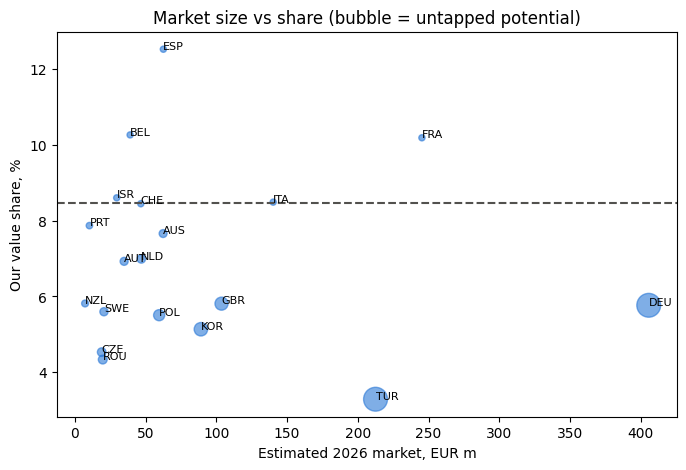

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ws.market_value_eur / 1e6, ws.share_value * 100, s=20 + ws.untapped_potential_eur / 4e4, color="#2A78D6", alpha=0.6)
for _, r in ws.iterrows():
    ax.annotate(r.iso3, (r.market_value_eur / 1e6, r.share_value * 100), fontsize=8)
ax.axhline(K["benchmark_share"] * 100, ls="--", color="#52514E")
ax.set_xlabel("Estimated 2026 market, EUR m"); ax.set_ylabel("Our value share, %")
ax.set_title("Market size vs share (bubble = untapped potential)")
plt.show()

## 2. What explains the gap to target? (SIMULATED)
Year to date = January-October. The price-volume-mix bridge must close exactly: the effects add up to the change in revenue.

In [5]:
ytd = pd.read_csv(OUT / "02_ytd_country.csv")
ytdp = pd.read_csv(OUT / "02_ytd_product.csv")
K["revenue_ytd_m"] = ytd.revenue_ytd.sum() / 1e6
K["target_ytd_m"] = ytd.target_ytd.sum() / 1e6
K["revenue_ytd_ly_m"] = ytd.revenue_ytd_ly.sum() / 1e6
K["gap_ytd_m"] = K["revenue_ytd_m"] - K["target_ytd_m"]
K["vs_target_ytd"] = K["revenue_ytd_m"] / K["target_ytd_m"] - 1
K["growth_ytd"] = K["revenue_ytd_m"] / K["revenue_ytd_ly_m"] - 1
K["target_fy_m"] = ytd.target_full_year.sum() / 1e6
neg = ytd[ytd.gap_to_target < 0].sort_values("gap_to_target")
K["gap_fra_deu_m"] = ytd.set_index("iso3").loc[["FRA", "DEU"], "gap_to_target"].sum() / 1e6
K["gap_fra_deu_share"] = K["gap_fra_deu_m"] / K["gap_ytd_m"]
K["countries_below_target"] = int((ytd.gap_to_target < 0).sum())
for iso in ["FRA", "DEU", "TUR", "POL", "KOR", "ESP"]:
    r = ytd.set_index("iso3").loc[iso]
    K[f"{iso.lower()}_vs_target"] = r.vs_target_pct
    K[f"{iso.lower()}_gap_m"] = r.gap_to_target / 1e6
    K[f"{iso.lower()}_growth"] = r.growth_yoy
ytd[["country", "revenue_ytd", "target_ytd", "gap_to_target", "vs_target_pct", "growth_yoy"]]

,country,revenue_ytd,target_ytd,gap_to_target,vs_target_pct,growth_yoy
0,Germany,"19,450,256.240","21,521,367.850","-2,071,111.610",-0.096,-0.045
1,France,"20,784,259.130","22,729,713.820","-1,945,454.690",-0.086,-0.034
2,United Kingdom,"4,998,867.960","5,721,996.830","-723,128.870",-0.126,-0.077
3,Italy,"9,942,996.160","10,324,677.770","-381,681.610",-0.037,0.018
4,Netherlands,"2,716,059.140","3,076,189.200","-360,130.060",-0.117,-0.076
5,Australia,"4,013,290.750","4,333,914.600","-320,623.850",-0.074,-0.012
6,Belgium,"3,363,347.920","3,574,882.080","-211,534.160",-0.059,-0.005
7,Switzerland,"3,292,621.900","3,456,649.540","-164,027.640",-0.047,0.007
8,Sweden,"951,593.740","1,065,468.570","-113,874.830",-0.107,-0.074
9,Czechia,"718,098.330","770,375.770","-52,277.440",-0.068,-0.006


In [6]:
pvm = pd.read_csv(OUT / "03_pvm_total.csv").set_index("step")
pvc = pd.read_csv(OUT / "03_pvm_country.csv")
pvp = pd.read_csv(OUT / "03_pvm_product.csv")
r0, r1 = pvm.loc["Revenue Jan-Oct 2025", "value"], pvm.loc["Revenue Jan-Oct 2026", "value"]
effects = pvm.loc[["Volume", "Mix", "Price"], "value"]
assert abs(effects.sum() - (r1 - r0)) < 0.01, "bridge does not close"
assert pvc.closure_check.abs().max() < 0.01
print(f"R0 {r0:,.0f} + volume {effects['Volume']:,.0f} + mix {effects['Mix']:,.0f} + price {effects['Price']:,.0f} "
      f"= {r0 + effects.sum():,.0f}  (R1 = {r1:,.0f})")
K["pvm_volume_m"], K["pvm_mix_m"], K["pvm_price_m"] = effects["Volume"] / 1e6, effects["Mix"] / 1e6, effects["Price"] / 1e6
K["pvm_change_m"] = (r1 - r0) / 1e6
des = pvp.set_index("product_id").loc["DES"]
K["des_price_change"] = des.price_change_pct
K["des_price_effect_m"] = des.price_effect / 1e6
K["des_price_share"] = des.price_effect / effects["Price"]
K["dcb_units_growth"] = pvp.set_index("product_id").loc["DCB", "units_growth"]
deu_pvm = pvc.set_index("iso3").loc["DEU"]
K["deu_price_effect_m"] = deu_pvm.price_effect / 1e6
fra_pvm = pvc.set_index("iso3").loc["FRA"]
K["fra_volume_effect_m"] = fra_pvm.volume_effect / 1e6
pvp

R0 94,108,467 + volume 3,817,864 + mix 1,411,269 + price -3,985,386 = 95,352,214  (R1 = 95,352,214)


,product_id,product_line,revenue_ly,revenue_cy,units_growth,price_effect,price_change_pct
0,DES,Coronary stents,"26,915,163.280","26,105,852.790",0.066,"-2,015,554.027",-0.072
1,PTB,PTCA balloons,"23,424,232.120","23,435,711.480",0.058,"-813,025.124",-0.034
2,DCB,Drug-coated balloons,"10,659,934.930","12,108,332.180",0.212,"-552,769.087",-0.044
3,PER,Peripheral devices,"13,301,263.920","13,461,405.340",0.063,"-328,652.451",-0.024
4,GWR,Guidewires,"10,484,735.700","10,670,876.240",0.052,"-145,992.364",-0.013
5,DXC,Diagnostic catheters,"9,323,136.950","9,570,036.130",0.063,"-129,392.540",-0.013


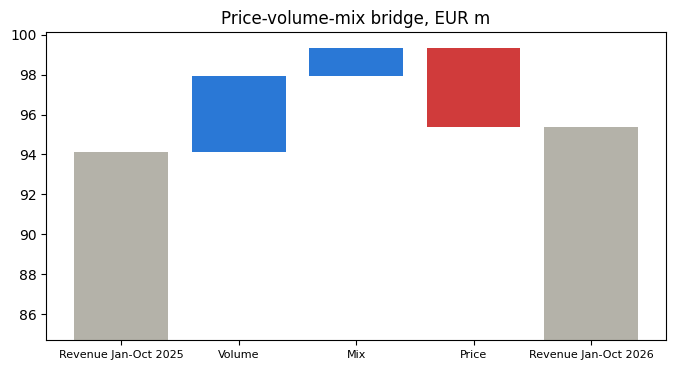

In [7]:
steps = ["Revenue Jan-Oct 2025", "Volume", "Mix", "Price", "Revenue Jan-Oct 2026"]
vals = pvm.loc[steps, "value"].values / 1e6
base = [0, vals[0], vals[0] + vals[1], vals[0] + vals[1] + vals[2], 0]
heights = [vals[0], vals[1], vals[2], vals[3], vals[4]]
colors = ["#B4B2A9", "#2A78D6", "#2A78D6", "#D03B3B", "#B4B2A9"]
fig, ax = plt.subplots(figsize=(8, 4))
for i, (b, h, c) in enumerate(zip(base, heights, colors)):
    ax.bar(i, h, bottom=b if i not in (0, 4) else 0, color=c)
ax.set_xticks(range(5), steps, fontsize=8); ax.set_ylim(vals[0] * 0.9, max(vals) * 1.05)
ax.set_title("Price-volume-mix bridge, EUR m"); plt.show()

## 3. Which hospitals carry growth, and which may leave? (SIMULATED)

In [8]:
acc = pd.read_csv(OUT / "04_accounts.csv")
K["accounts_active"] = int((acc.revenue_l12m > 0).sum())
top20 = acc[acc.size_percentile < 0.2]
K["top20_accounts"] = len(top20)
K["top20_revenue_share"] = top20.revenue_l12m.sum() / acc.revenue_l12m.sum()
K["accounts_for_80pct"] = int((acc.cum_revenue_share < 0.8).sum() + 1)
K["accounts_for_80pct_share"] = K["accounts_for_80pct"] / K["accounts_active"]
risk = acc[acc.risk_flag != "OK"]
K["at_risk_accounts"] = len(risk)
K["at_risk_l3m_ly_k"] = risk.revenue_l3m_ly.sum() / 1e3
K["at_risk_l3m_k"] = risk.revenue_l3m.sum() / 1e3
K["at_risk_lost_run_rate_m"] = (risk.revenue_l3m_ly.sum() - risk.revenue_l3m.sum()) * 4 / 1e6   # annualised
K["at_risk_l12m_share"] = risk.revenue_l12m.sum() / acc.revenue_l12m.sum()
K["at_risk_fra"] = int((risk.iso3 == "FRA").sum())
new = acc[acc.is_new_account]
K["new_accounts"] = len(new)
K["new_accounts_revenue_share"] = new.revenue_l12m.sum() / acc.revenue_l12m.sum()
K["new_accounts_tur"] = int((new.iso3 == "TUR").sum())
seg = (acc.groupby("segment").agg(accounts=("account_id", "count"), revenue_l12m=("revenue_l12m", "sum"),
                                  revenue_p12m=("revenue_p12m", "sum"))
       .assign(revenue_share=lambda d: d.revenue_l12m / d.revenue_l12m.sum(),
               growth=lambda d: d.revenue_l12m / d.revenue_p12m - 1))
seg.reset_index().to_csv(OUT / "04_segments.csv", index=False)
K["seg_defend_accounts"] = int(seg.loc["2 · Big & declining: defend", "accounts"])
K["seg_defend_share"] = seg.loc["2 · Big & declining: defend", "revenue_share"]
risk[["account_id", "country", "account_type", "revenue_l3m_ly", "revenue_l3m", "growth_l3m"]].sort_values("revenue_l3m_ly", ascending=False)

,account_id,country,account_type,revenue_l3m_ly,revenue_l3m,growth_l3m
8,FR-054,France,University hospital,"461,793.510","123,030.260",-0.734
24,DE-012,Germany,Public general hospital,"292,494.410","76,435.490",-0.739
26,GB-002,United Kingdom,Public general hospital,"284,521.440","28,800.090",-0.899
17,IT-035,Italy,University hospital,"263,206.290","181,335.080",-0.311
32,AU-007,Australia,Private hospital,"240,257.880","146,588.970",-0.390
35,NL-001,Netherlands,Public general hospital,"212,010.410","116,822.840",-0.449
54,FR-033,France,Public general hospital,"186,984.840","62,020.720",-0.668
51,FR-029,France,Public general hospital,"180,385.380","82,694.940",-0.542
108,IT-032,Italy,Cardiac centre,"85,049.300","54,388.160",-0.361
151,BE-007,Belgium,University hospital,"83,207.340","21,975.210",-0.736


**Does the alert find the right hospitals?** The simulation keeps an answer key of the events it built in
(`data/clean/simulation_answer_key.csv`, not loaded into the database). The alert is scored against it.

In [9]:
key = pd.read_csv("data/clean/simulation_answer_key.csv")
lost = set(key.loc[key.event.str.startswith("competitor"), "account_id"])
flagged = set(risk.account_id)
K["alert_true_positives"] = len(flagged & lost)
K["alert_false_alarms"] = len(flagged - lost)
K["alert_missed"] = len(lost - flagged)
print(f"injected competitor wins: {len(lost)} | flagged: {len(flagged)} | caught: {K['alert_true_positives']} | "
      f"false alarms: {K['alert_false_alarms']} | missed: {K['alert_missed']}")

injected competitor wins: 10 | flagged: 10 | caught: 10 | false alarms: 0 | missed: 0


In [10]:
seg

,accounts,revenue_l12m,revenue_p12m,revenue_share,growth
segment,,,,,
1 · Big & growing: protect,36,"40,320,337.510","37,313,888.860",0.354,0.081
2 · Big & declining: defend,33,"26,949,505.710","30,224,699.340",0.236,-0.108
3 · Smaller & growing: develop,86,"15,821,642.560","14,133,784.640",0.139,0.119
4 · Smaller & flat or declining: serve efficiently,161,"27,788,941.340","29,281,939.070",0.244,-0.051
5 · New (since 2025),35,"3,147,055.930","1,116,672.520",0.028,1.818


## 4. Will we hit the annual target? Forecast validated on a hold-out (SIMULATED)
Model, per country: **forecast(month m) = revenue(m - 12) x g**, where g = last 12 months / the 12 months before at the
forecast origin. It keeps each country's seasonality (August holidays, Lunar New Year...) and its recent growth.
**Validation**: origin April 2026, forecast May-October 2026 (6 months the model never saw), compare with actuals,
and with a naive baseline (same month last year, g = 1).

In [11]:
fi = pd.read_csv(OUT / "05_forecast_inputs.csv", parse_dates=["month"])
piv = fi.pivot(index="month", columns="iso3", values="revenue_eur").sort_index()

def seasonal_growth_forecast(history, horizon, use_growth=True):
    """history: month x country revenue up to the origin. Returns month x country forecasts for the next `horizon` months."""
    origin = history.index.max()
    g = history.iloc[-12:].sum() / history.iloc[-24:-12].sum() if use_growth else pd.Series(1.0, index=history.columns)
    months = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    return pd.DataFrame({m: history.loc[m - pd.DateOffset(years=1)] * g for m in months}).T, g

def mape(actual, pred):
    return float((abs(actual - pred) / actual).mean())

HOLD_ORIGIN = pd.Timestamp("2026-04-01")
hist = piv.loc[:HOLD_ORIGIN]
pred, g_hold = seasonal_growth_forecast(hist, 6)
naive, _ = seasonal_growth_forecast(hist, 6, use_growth=False)
act = piv.loc[pred.index]
models = pd.DataFrame({
    "model": ["Seasonal x trailing growth", "Naive: same month last year"],
    "mape_total": [mape(act.sum(axis=1), pred.sum(axis=1)), mape(act.sum(axis=1), naive.sum(axis=1))],
    "mape_country_median": [np.median([mape(act[c], pred[c]) for c in act]), np.median([mape(act[c], naive[c]) for c in act])],
    "error_6m_total": [pred.values.sum() / act.values.sum() - 1, naive.values.sum() / act.values.sum() - 1],
})
models.to_csv(OUT / "05_forecast_models.csv", index=False)
K["mape_total"] = models.loc[0, "mape_total"]
K["mape_naive_total"] = models.loc[1, "mape_total"]
K["mape_country_median"] = models.loc[0, "mape_country_median"]
K["holdout_bias"] = models.loc[0, "error_6m_total"]
country_mape = pd.Series({c: mape(act[c], pred[c]) for c in act}, name="holdout_mape")
# Why does the model over-forecast the hold-out? Compare with what the at-risk accounts lost over the same months.
sales = pd.read_csv("data/clean/sales.csv", parse_dates=["month"])
ar = sales[sales.account_id.isin(acc.loc[acc.risk_flag != "OK", "account_id"])]
lost_hold = (ar[ar.month.between("2025-05-01", "2025-10-01")].revenue_eur.sum()
             - ar[ar.month.between("2026-05-01", "2026-10-01")].revenue_eur.sum())
K["holdout_overforecast_m"] = (pred.values.sum() - act.values.sum()) / 1e6
K["holdout_at_risk_drop_m"] = lost_hold / 1e6
print(f"over-forecast {K['holdout_overforecast_m']:.2f} m vs at-risk accounts' drop {K['holdout_at_risk_drop_m']:.2f} m")
models

over-forecast 1.75 m vs at-risk accounts' drop 1.76 m


,model,mape_total,mape_country_median,error_6m_total
0,Seasonal x trailing growth,0.031,0.065,0.031
1,Naive: same month last year,0.018,0.080,-0.005


In [12]:
FINAL_ORIGIN = AS_OF
fc, g_final = seasonal_growth_forecast(piv.loc[:FINAL_ORIGIN], 2)        # November and December 2026
tgt = fi.pivot(index="month", columns="iso3", values="target_eur")
# targets for the forecast months come from targets.csv (02 only kept months up to the as-of month)
targets = pd.read_csv("data/clean/targets.csv", parse_dates=["month"])
tgt_fy = targets[targets.month.dt.year == 2026].groupby("iso3").target_eur.sum()
ytd_c = piv.loc["2026-01-01":FINAL_ORIGIN].sum()
by_c = pd.DataFrame({"revenue_ytd": ytd_c, "forecast_nov_dec": fc.sum(), "target_fy": tgt_fy,
                     "growth_factor": g_final, "holdout_mape": country_mape})
by_c["forecast_fy"] = by_c.revenue_ytd + by_c.forecast_nov_dec
by_c["gap_fy"] = by_c.forecast_fy - by_c.target_fy
by_c["vs_target_fy"] = by_c.forecast_fy / by_c.target_fy - 1
by_c = by_c.join(pd.read_csv("data/clean/countries.csv").set_index("iso3")[["country", "region"]])
by_c.sort_values("gap_fy").reset_index().rename(columns={"index": "iso3"}).to_csv(OUT / "05_forecast_country.csv", index=False)

fy = by_c.forecast_fy.sum()
K["forecast_nov_dec_m"] = by_c.forecast_nov_dec.sum() / 1e6
K["forecast_fy_m"] = fy / 1e6
K["target_fy_check_m"] = by_c.target_fy.sum() / 1e6
K["forecast_gap_m"] = (fy - by_c.target_fy.sum()) / 1e6
K["forecast_vs_target"] = fy / by_c.target_fy.sum() - 1
K["fy_2025_m"] = piv.loc["2025-01-01":"2025-12-01"].values.sum() / 1e6
K["forecast_growth_fy"] = fy / 1e6 / K["fy_2025_m"] - 1
K["countries_fy_on_target"] = int((by_c.gap_fy >= 0).sum())
need = by_c.target_fy.sum() - by_c.revenue_ytd.sum()
K["needed_nov_dec_m"] = need / 1e6
K["needed_uplift"] = need / by_c.forecast_nov_dec.sum() - 1
by_c.sort_values("gap_fy")[["country", "revenue_ytd", "forecast_nov_dec", "forecast_fy", "target_fy", "gap_fy", "holdout_mape"]]

,country,revenue_ytd,forecast_nov_dec,forecast_fy,target_fy,gap_fy,holdout_mape
DEU,Germany,"19,450,256.240","3,784,117.544","23,234,373.784","25,681,253.870","-2,446,880.086",0.042
FRA,France,"20,784,259.130","4,096,482.953","24,880,742.083","27,179,984.100","-2,299,242.017",0.052
GBR,United Kingdom,"4,998,867.960","960,757.365","5,959,625.325","6,802,688.130","-843,062.805",0.107
ITA,Italy,"9,942,996.160","1,984,999.528","11,927,995.688","12,394,023.280","-466,027.592",0.026
NLD,Netherlands,"2,716,059.140","529,382.102","3,245,441.242","3,667,921.360","-422,480.118",0.136
AUS,Australia,"4,013,290.750","751,274.228","4,764,564.978","5,149,457.250","-384,892.272",0.031
BEL,Belgium,"3,363,347.920","641,335.318","4,004,683.238","4,258,421.090","-253,737.852",0.030
CHE,Switzerland,"3,292,621.900","650,640.487","3,943,262.387","4,139,285.610","-196,023.223",0.028
SWE,Sweden,"951,593.740","189,099.838","1,140,693.578","1,271,545.760","-130,852.182",0.065
CZE,Czechia,"718,098.330","140,243.875","858,342.205","920,385.760","-62,043.555",0.080


In [13]:
# Scenarios for November-December: the hold-out error gives the band; the at-risk accounts give a recovery case.
band = K["mape_total"]
nd = by_c.forecast_nov_dec.sum()
recover = (risk.revenue_l3m_ly.sum() - risk.revenue_l3m.sum()) / 3 * 2 * 0.5     # win back half of the lost run-rate for 2 months
naive_fc, _ = seasonal_growth_forecast(piv.loc[:FINAL_ORIGIN], 2, use_growth=False)
scen = pd.DataFrame([
    ("Low: forecast - hold-out error", by_c.revenue_ytd.sum() + nd * (1 - band)),
    ("Naive: Nov-Dec = last year", by_c.revenue_ytd.sum() + naive_fc.values.sum()),
    ("Base forecast", fy),
    ("High: forecast + hold-out error", by_c.revenue_ytd.sum() + nd * (1 + band)),
    ("Base + win back half of at-risk accounts", fy + recover),
], columns=["scenario", "revenue_fy"])
scen["target_fy"] = by_c.target_fy.sum()
scen["gap"] = scen.revenue_fy - scen.target_fy
scen["vs_target"] = scen.revenue_fy / scen.target_fy - 1
scen["order"] = range(1, len(scen) + 1)
scen.to_csv(OUT / "05_forecast_scenarios.csv", index=False)
K["scenario_low_vs_target"] = scen.vs_target.min()
K["scenario_best_vs_target"] = scen.vs_target.max()
K["scenario_best_gap_m"] = scen.gap.max() / 1e6
K["scenario_recover_gain_m"] = recover / 1e6
scen

,scenario,revenue_fy,target_fy,gap,vs_target,order
0,Low: forecast - hold-out error,"113,850,418.931","120,872,986.120","-7,022,567.189",-0.058,1
1,Naive: Nov-Dec = last year,"114,027,483.050","120,872,986.120","-6,845,503.070",-0.057,2
2,Base forecast,"114,436,742.814","120,872,986.120","-6,436,243.306",-0.053,3
3,High: forecast + hold-out error,"115,023,066.697","120,872,986.120","-5,849,919.423",-0.048,4
4,Base + win back half of at-risk accounts,"114,902,015.827","120,872,986.120","-5,970,970.293",-0.049,5


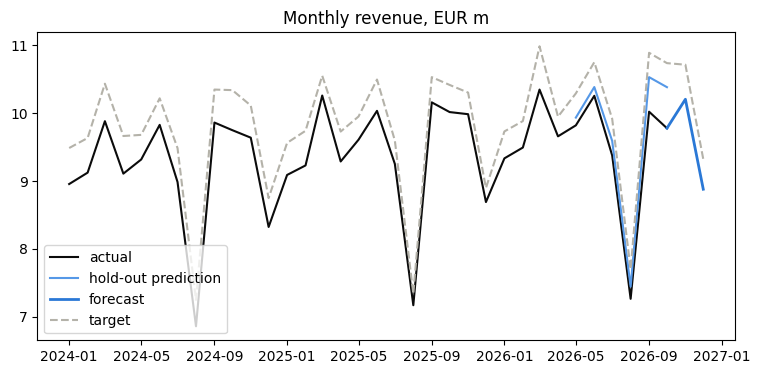

In [14]:
# Monthly series for the report: actual, hold-out prediction, forecast and target (all countries)
tot = pd.DataFrame({"actual": piv.sum(axis=1)})
tot["holdout_pred"] = pred.sum(axis=1)
tot = tot.reindex(pd.date_range("2024-01-01", "2026-12-01", freq="MS"))
tot.loc[fc.index, "forecast"] = fc.sum(axis=1)
tot.loc[AS_OF, "forecast"] = tot.loc[AS_OF, "actual"]          # joins the forecast line to the last actual
tot["target"] = targets.groupby("month").target_eur.sum()
tot.loc[tot.index > AS_OF, "actual"] = np.nan
tot.index.name = "month"
tot.reset_index().to_csv(OUT / "05_forecast_monthly.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tot.index, tot.actual / 1e6, color="#0B0B0B", label="actual")
ax.plot(tot.index, tot.holdout_pred / 1e6, color="#5598E7", label="hold-out prediction")
ax.plot(tot.index, tot.forecast / 1e6, color="#2A78D6", ls="-", lw=2, label="forecast")
ax.plot(tot.index, tot.target / 1e6, color="#B4B2A9", ls="--", label="target")
ax.legend(); ax.set_title("Monthly revenue, EUR m"); plt.show()

## 5. Save the numbers used in the report

In [15]:
kp = pd.DataFrame([(k, v) for k, v in K.items()], columns=["key", "value"])
kp.to_csv(OUT / "kpis.csv", index=False)
print(len(kp), "numbers -> data/output/kpis.csv")
kp

104 numbers -> data/output/kpis.csv


,key,value
0,as_of_month,202610
1,countries,19
2,pci_total,1612229
3,market_value_total_m,"1,654.559"
4,revenue_l12m_m,114.027
...,...,...
99,needed_uplift,0.337
100,scenario_low_vs_target,-0.058
101,scenario_best_vs_target,-0.048
102,scenario_best_gap_m,-5.850
